In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)


Pandas: 3.0.5
NumPy: 2.5.2
Matplotlib: 3.11.1
Seaborn: 0.13.2


In [2]:
df = pd.read_excel("D:/Telco-Customer-Churn-EDA/data/Customer_Churn_Dataset.xlsx")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,numAdminTickets,numTechTickets,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,0,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.5,0,0,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,0,0,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,3,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,0,0,Yes


In [4]:
df.shape


(7043, 23)

In [5]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'numAdminTickets',
       'numTechTickets', 'Churn'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [7]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
numAdminTickets     0
numTechTickets      0
Churn               0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["TotalCharges"].head(10)

0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: object

In [10]:
df["TotalCharges"].unique()[:20]

array([29.85, 1889.5, 108.15, 1840.75, 151.65, 820.5, 1949.4, 301.9,
       3046.05, 3487.95, 587.45, 326.8, 5681.1, 5036.3, 2686.05, 7895.15,
       1022.95, 7382.25, 528.35, 1862.9], dtype=object)

In [11]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [12]:
df["TotalCharges"].isnull().sum()

np.int64(11)

In [13]:
df["TotalCharges"].dtype

dtype('float64')

In [14]:
df["gender"].unique()

<StringArray>
['Female', 'Male']
Length: 2, dtype: str

In [15]:
df["Partner"].unique()

<StringArray>
['Yes', 'No']
Length: 2, dtype: str

In [16]:
df["Dependents"].unique()

<StringArray>
['No', 'Yes']
Length: 2, dtype: str

In [17]:
df["Contract"].unique()

<StringArray>
['Month-to-month', 'One year', 'Two year']
Length: 3, dtype: str

In [18]:
df["InternetService"].unique()

<StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str

In [19]:
df["PaymentMethod"].unique()

<StringArray>
[         'Electronic check',              'Mailed check',
 'Bank transfer (automatic)',   'Credit card (automatic)']
Length: 4, dtype: str

In [20]:
df["Churn"].unique()

<StringArray>
['No', 'Yes']
Length: 2, dtype: str

In [21]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,numAdminTickets,numTechTickets
count,7043.000000,7043.000000,7043.000000,7032.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2283.300441,0.515689,0.419566
std,0.368612,24.559481,30.090047,2266.771362,1.275299,1.250117
min,0.000000,0.000000,18.250000,18.800000,0.000000,0.000000
25%,0.000000,9.000000,35.500000,401.450000,0.000000,0.000000
50%,0.000000,29.000000,70.350000,1397.475000,0.000000,0.000000
75%,0.000000,55.000000,89.850000,3794.737500,0.000000,0.000000
max,1.000000,72.000000,118.750000,8684.800000,5.000000,9.000000


In [22]:
df[df["TotalCharges"].isnull()][["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [23]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [24]:
df.isnull().sum().sum()

np.int64(0)

In [25]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [26]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [27]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

## Visualization

## 1. Customer Churn Distribution

The dataset contains 7,043 customers.

- 5,174 customers (73.46%) did not churn.
- 1,869 customers (26.54%) churned.

This shows that approximately one-fourth of the customers have left the telecom service. The churned customers form a smaller but significant group, which will be important for churn prediction.

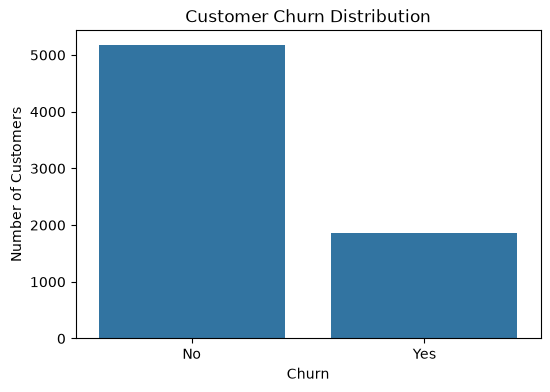

In [28]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [29]:
pd.crosstab(df["Contract"], df["Churn"])

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [30]:
pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


## 2. Contract Type vs Customer Churn

Contract type has a strong relationship with customer churn.

Month-to-month customers have the highest churn rate at 42.71%, while customers with one-year and two-year contracts have much lower churn rates of 11.27% and 2.83%, respectively.

This suggests that customers with longer-term contracts are more likely to remain with the telecom company.

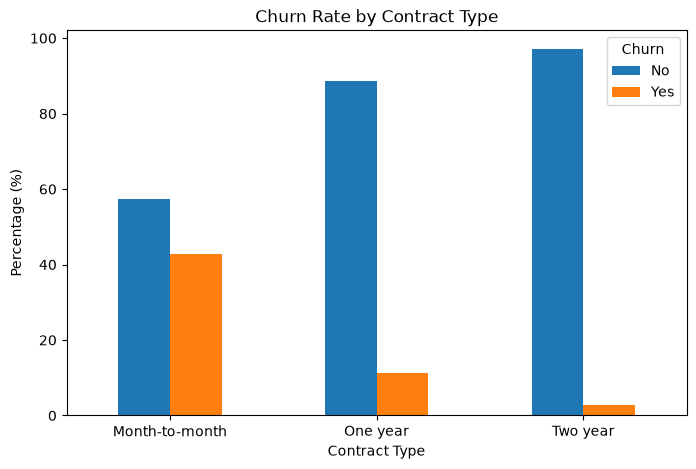

In [31]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")

plt.show()

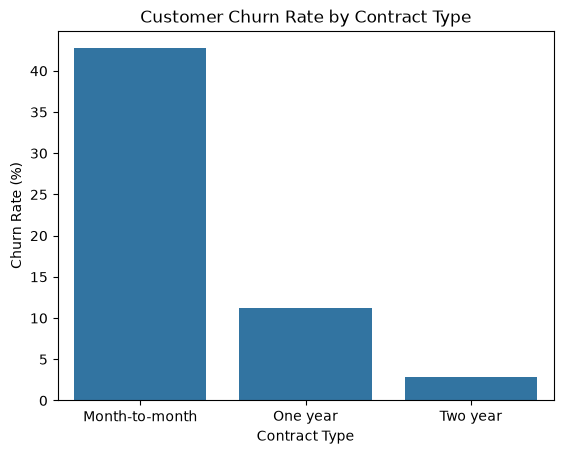

In [32]:
churn_rate = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
)

sns.barplot(
    data=churn_rate,
    x="Contract",
    y="ChurnRate"
)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.show()

In [33]:
pd.crosstab(df["tenure"], df["Churn"], normalize="index") * 100

Churn,No,Yes
tenure,,
0,100.000000,0.000000
1,38.009788,61.990212
2,48.319328,51.680672
3,53.000000,47.000000
4,52.840909,47.159091
...,...,...
68,91.000000,9.000000
69,91.578947,8.421053
70,90.756303,9.243697


In [34]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 6, 12, 24, 48, 60, 72],
    labels=[
        "0-6 months",
        "7-12 months",
        "13-24 months",
        "25-48 months",
        "49-60 months",
        "61-72 months"
    ]
)

In [35]:
tenure_churn = (
    df.groupby("TenureGroup", observed=True)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
)

tenure_churn

,TenureGroup,ChurnRate
0,0-6 months,52.937205
1,7-12 months,35.886525
2,13-24 months,28.710938
3,25-48 months,20.388959
4,49-60 months,14.423077
5,61-72 months,6.609808


## 3. Tenure vs Customer Churn

Customer tenure shows a strong relationship with churn.

Customers with shorter tenure have considerably higher churn rates, while long-term customers are much less likely to leave. This indicates that the early stage of the customer relationship is a critical period for retention.

The analysis suggests that the company should focus on improving onboarding and engagement during the first few months of service.

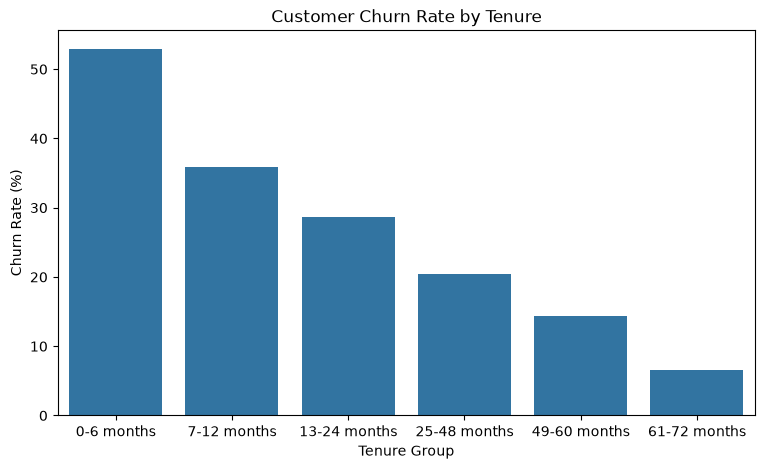

In [36]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=tenure_churn,
    x="TenureGroup",
    y="ChurnRate"
)

plt.title("Customer Churn Rate by Tenure")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [37]:
df.groupby("Churn")["MonthlyCharges"].mean()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

## 4. Monthly Charges vs Customer Churn

Customers who churned had a higher average monthly charge than customers who stayed.

The average monthly charge was 74.44 for churned customers compared with 61.27 for customers who stayed. This suggests that higher monthly charges may be associated with a greater likelihood of churn.

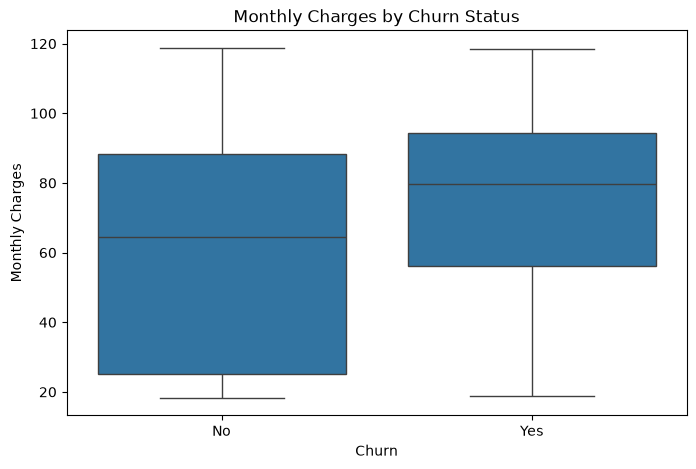

In [38]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

In [39]:
df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].mean()

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.569965,61.265124,2549.911442
Yes,17.979133,74.441332,1531.796094


## 5. Tenure, Monthly Charges and Total Charges vs Churn

Churned customers have a substantially lower average tenure than customers who stayed. The average tenure of churned customers is approximately 18 months compared with 38 months for customers who stayed.

Churned customers also have higher average monthly charges. However, their average total charges are lower because they generally have shorter customer relationships.

These findings suggest that short-tenure customers with relatively high monthly charges may be an important high-risk segment for customer retention.

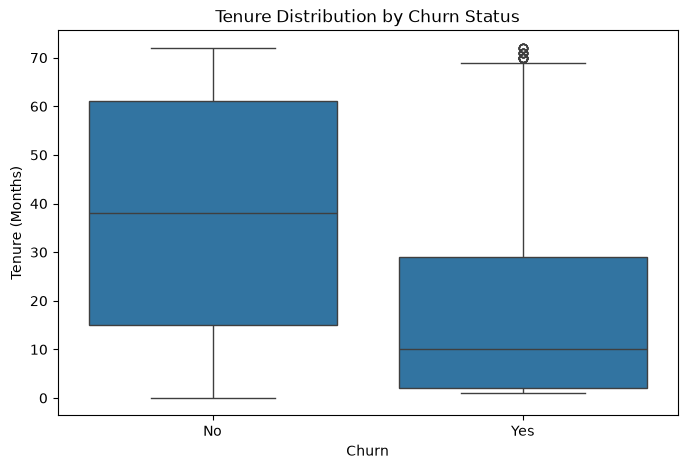

In [40]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Tenure Distribution by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

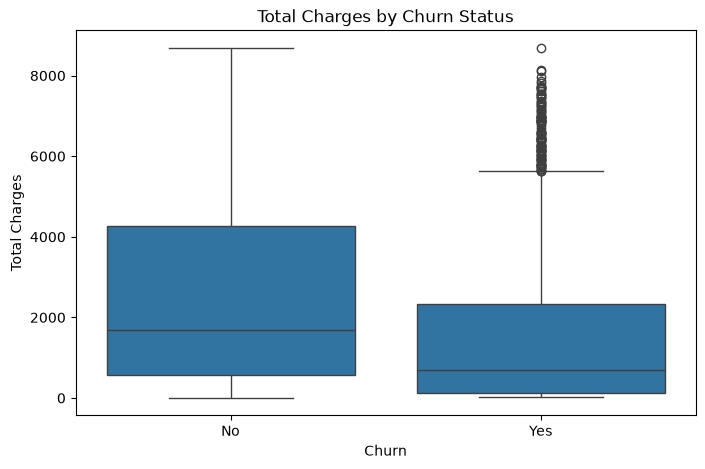

In [41]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="TotalCharges"
)

plt.title("Total Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Total Charges")

plt.show()

In [42]:
pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


## 6. Internet Service vs Customer Churn

Internet service type shows a noticeable relationship with customer churn.

Fiber optic customers have the highest churn rate at 41.89%, followed by DSL customers at 18.96%. Customers without internet service have the lowest churn rate at 7.40%.

The high churn rate among fiber optic customers should be investigated further, particularly in relation to monthly charges, contract type, and technical support.

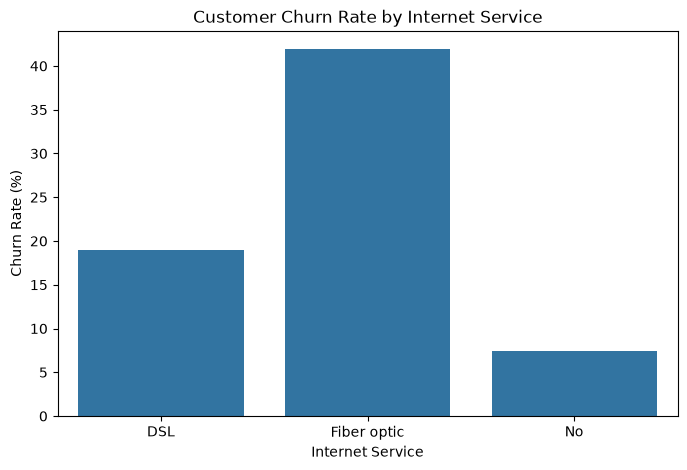

In [43]:
internet_churn = (
    df.groupby("InternetService")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=internet_churn,
    x="InternetService",
    y="ChurnRate"
)

plt.title("Customer Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")

plt.show()

In [44]:
pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


## 7. Payment Method vs Customer Churn

Payment method shows a strong relationship with customer churn.

Customers using electronic checks have the highest churn rate at 45.29%. In comparison, customers using automatic bank transfer and automatic credit card payments have much lower churn rates of 16.71% and 15.24%, respectively.

This segment should be investigated further to determine whether payment method is related to other churn factors such as contract type, tenure, or monthly charges.

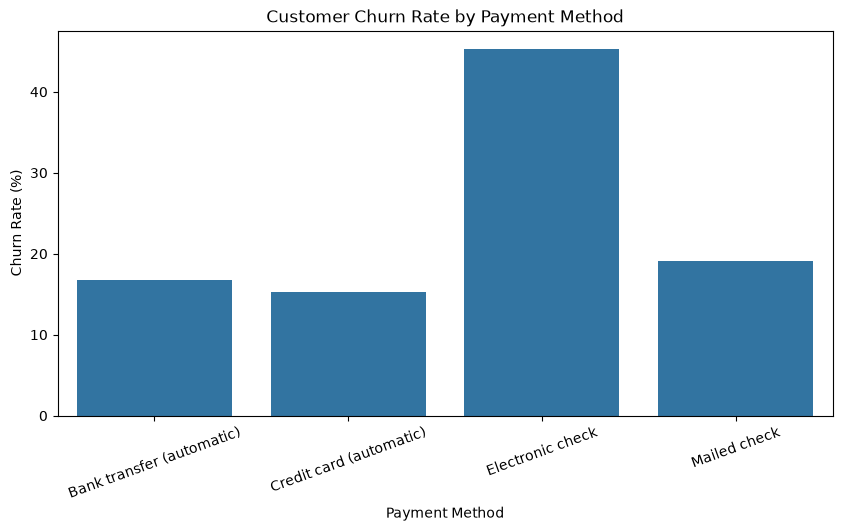

In [45]:
payment_churn = (
    df.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=payment_churn,
    x="PaymentMethod",
    y="ChurnRate"
)

plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20)

plt.show()

In [46]:
pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
OnlineSecurity,,
No,58.233276,41.766724
No internet service,92.595020,7.404980
Yes,85.388806,14.611194


In [47]:
pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
TechSupport,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


## 8. Online Security vs Customer Churn

Customers without online security have a churn rate of 41.77%, while customers with online security have a much lower churn rate of 14.61%.

This indicates that online security subscription is associated with lower customer churn. The company could investigate whether promoting security services as part of customer packages may improve retention.

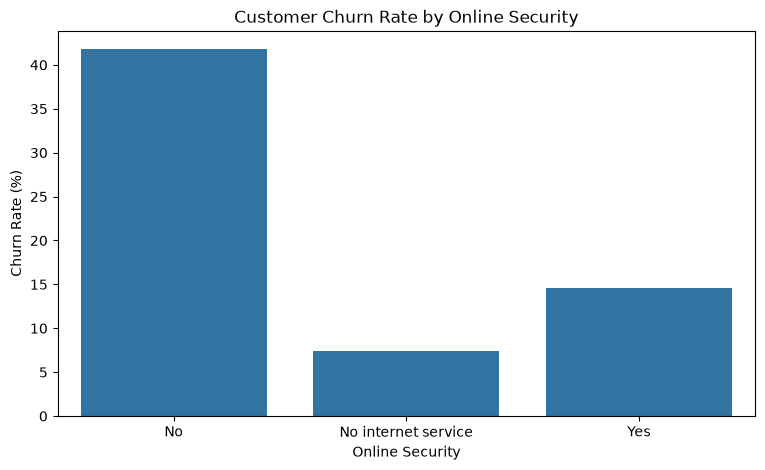

In [48]:
online_security_churn = (
    df.groupby("OnlineSecurity")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=online_security_churn,
    x="OnlineSecurity",
    y="ChurnRate"
)

plt.title("Customer Churn Rate by Online Security")
plt.xlabel("Online Security")
plt.ylabel("Churn Rate (%)")

plt.show()

## 9. Tech Support vs Customer Churn

Customers without tech support have a churn rate of 41.64%, compared with 15.17% for customers who have tech support.

This suggests that access to technical support is associated with improved customer retention.

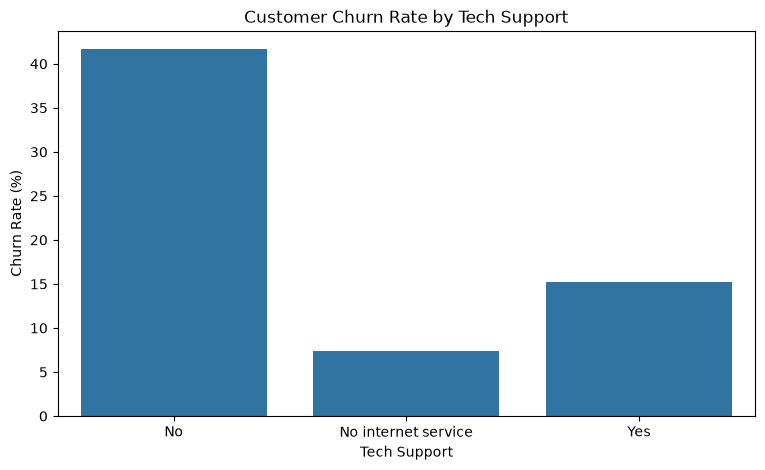

In [49]:
tech_support_churn = (
    df.groupby("TechSupport")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=tech_support_churn,
    x="TechSupport",
    y="ChurnRate"
)

plt.title("Customer Churn Rate by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Churn Rate (%)")

plt.show()

In [50]:
df.groupby("Churn")[["numAdminTickets", "numTechTickets"]].mean()

,numAdminTickets,numTechTickets
Churn,,
No,0.530924,0.151140
Yes,0.473515,1.162654


## 10. Technical Support Tickets vs Customer Churn

Technical support ticket volume shows a strong relationship with customer churn.

Churned customers raised an average of 1.16 technical support tickets, compared with only 0.15 tickets among customers who stayed. This suggests that customers experiencing technical issues may be at higher risk of churn.

The telecom company could monitor repeated technical support requests and proactively contact customers who experience frequent technical problems.

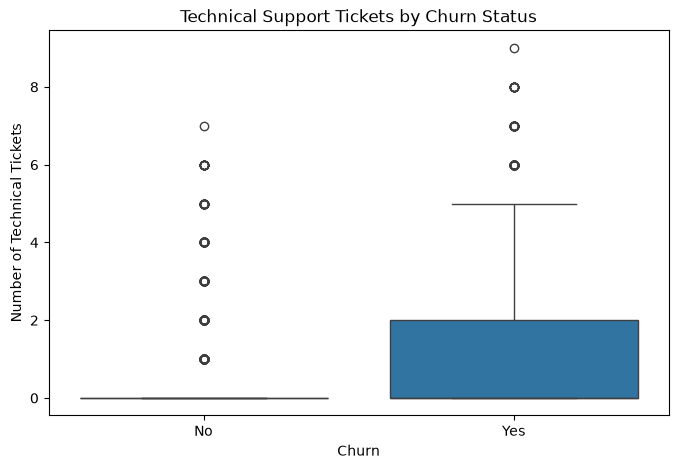

In [51]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="numTechTickets"
)

plt.title("Technical Support Tickets by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Number of Technical Tickets")

plt.show()

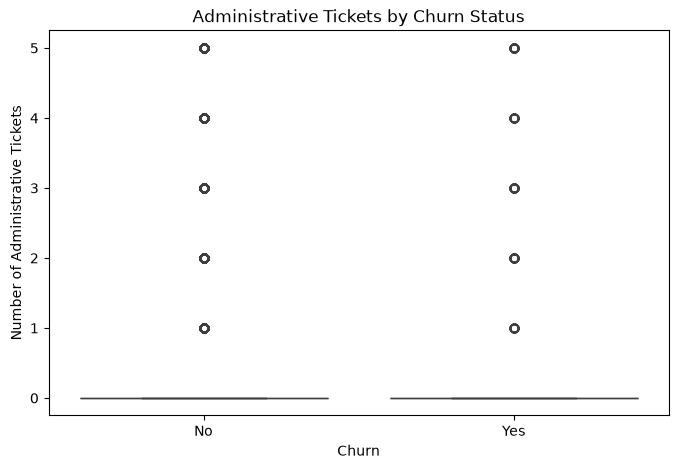

In [52]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="numAdminTickets"
)

plt.title("Administrative Tickets by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Number of Administrative Tickets")

plt.show()

In [53]:
pd.crosstab(
    [df["Contract"], df["InternetService"]],
    df["Churn"],
    normalize="index"
) * 100

Churn                                  No        Yes
Contract       InternetService                      
Month-to-month DSL              67.784137  32.215863
               Fiber optic      45.394737  54.605263
               No               81.106870  18.893130
One year       DSL              90.701754   9.298246
               Fiber optic      80.705009  19.294991
               No               97.527473   2.472527
Two year       DSL              98.089172   1.910828
               Fiber optic      92.773893   7.226107
               No               99.216301   0.783699

## 11. Contract and Internet Service vs Customer Churn

Combining contract type and internet service reveals a stronger churn pattern than analyzing either variable separately.

Month-to-month customers using fiber optic service have the highest observed churn rate at 54.61%. In comparison, fiber optic customers on two-year contracts have a much lower churn rate of 7.23%.

This suggests that contract commitment may play an important role in the relationship between internet service and customer churn. The month-to-month fiber optic segment should therefore be considered a high-risk customer group.

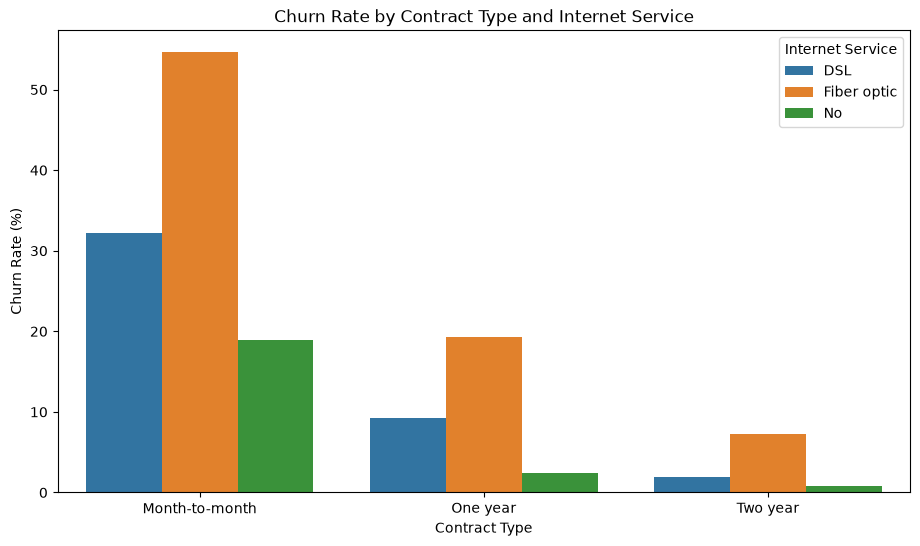

In [54]:
contract_internet_churn = (
    df.groupby(["Contract", "InternetService"])["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=contract_internet_churn,
    x="Contract",
    y="ChurnRate",
    hue="InternetService"
)

plt.title("Churn Rate by Contract Type and Internet Service")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.legend(title="Internet Service")

plt.show()

In [55]:
pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
SeniorCitizen,,
0,76.393832,23.606168
1,58.318739,41.681261


In [56]:
pd.crosstab(
    df["Dependents"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
Dependents,,
No,68.720860,31.279140
Yes,84.549763,15.450237


In [57]:
pd.crosstab(
    df["Partner"],
    df["Churn"],
    normalize="index"
) * 100


Churn,No,Yes
Partner,,
No,67.042021,32.957979
Yes,80.335097,19.664903


## 12. Demographic Factors vs Customer Churn

Demographic characteristics also show differences in observed churn rates.

Senior citizens have a higher churn rate of 41.68% compared with 23.61% for non-senior customers.

Customers without dependents have a churn rate of 31.28%, compared with 15.45% for customers with dependents.

Similarly, customers without a partner have a churn rate of 32.96%, compared with 19.66% for customers with a partner.

These variables may provide additional information for the churn prediction model.

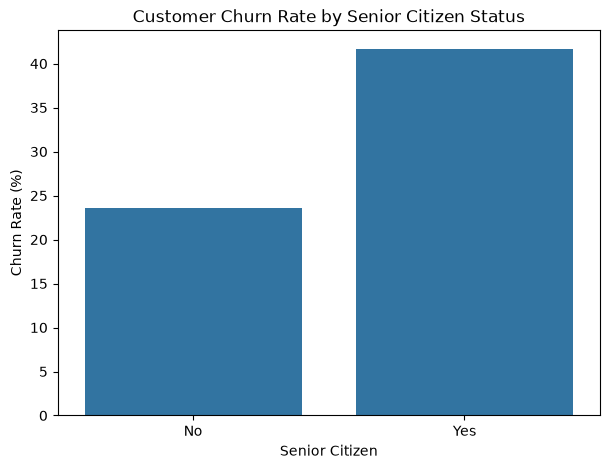

In [58]:
senior_churn = (
    df.groupby("SeniorCitizen")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
)

senior_churn["SeniorCitizen"] = senior_churn["SeniorCitizen"].map({
    0: "No",
    1: "Yes"
})

plt.figure(figsize=(7, 5))

sns.barplot(
    data=senior_churn,
    x="SeniorCitizen",
    y="ChurnRate"
)

plt.title("Customer Churn Rate by Senior Citizen Status")
plt.xlabel("Senior Citizen")
plt.ylabel("Churn Rate (%)")

plt.show()

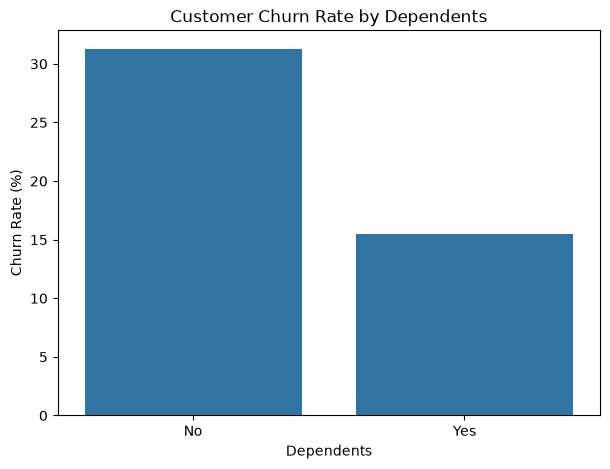

In [59]:
dependent_churn = (
    df.groupby("Dependents")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=dependent_churn,
    x="Dependents",
    y="ChurnRate"
)

plt.title("Customer Churn Rate by Dependents")
plt.xlabel("Dependents")
plt.ylabel("Churn Rate (%)")

plt.show()

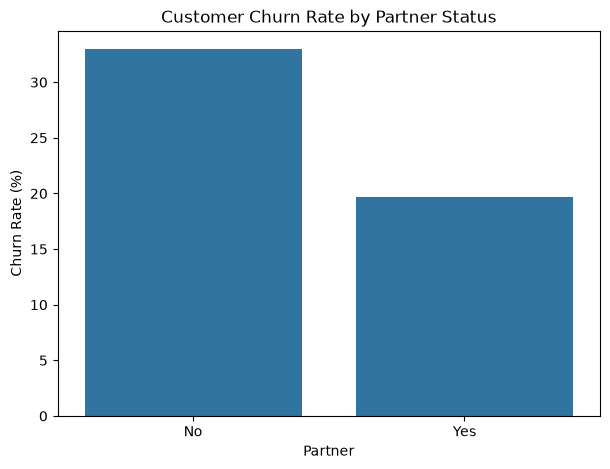

In [60]:
partner_churn = (
    df.groupby("Partner")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=partner_churn,
    x="Partner",
    y="ChurnRate"
)

plt.title("Customer Churn Rate by Partner Status")
plt.xlabel("Partner")
plt.ylabel("Churn Rate (%)")

plt.show()

In [61]:
df.columns 

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'numAdminTickets',
       'numTechTickets', 'Churn', 'TenureGroup'],
      dtype='str')

In [62]:
ml_df = df.copy()

ml_df = ml_df.drop(columns=["customerID"])

In [63]:
ml_df["Churn"] = ml_df["Churn"].map({
    "No": 0,
    "Yes": 1
})

In [64]:
ml_df["Churn"].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [65]:
ml_df = ml_df.drop(columns=["TenureGroup"])

In [66]:
X = ml_df.drop(columns=["Churn"])
y = ml_df["Churn"]

In [67]:
X.shape

(7043, 21)

In [68]:
y.shape

(7043,)

In [69]:
categorical_cols = X.select_dtypes(include=["object"]).columns
numerical_cols = X.select_dtypes(exclude=["object"]).columns

print("Categorical columns:")
print(list(categorical_cols))

print("\nNumerical columns:")
print(list(numerical_cols))

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'numAdminTickets', 'numTechTickets']


C:\Users\jyoti\AppData\Local\Temp\ipykernel_23264\2608627827.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include=["object"]).columns


In [70]:
categorical_cols = X.select_dtypes(include=["str"]).columns
numerical_cols = X.select_dtypes(exclude=["str"]).columns

print("Categorical columns:")
print(list(categorical_cols))

print("\nNumerical columns:")
print(list(numerical_cols))

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'numAdminTickets', 'numTechTickets']


In [72]:
from sklearn.model_selection import train_test_split

In [73]:
# Separate features and target
X = df.drop(columns=["Churn", "customerID", "TenureGroup"])
y = df["Churn"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7043, 21)
y shape: (7043,)
